## **10.1: Fish Harvest**

M = 1.0 Final loss: -0.0775644467766694
M = 1.0 Training time: 11.244466304779053 seconds
M = 10.0 Final loss: -3.8565235721236957
M = 10.0 Training time: 11.327390909194946 seconds


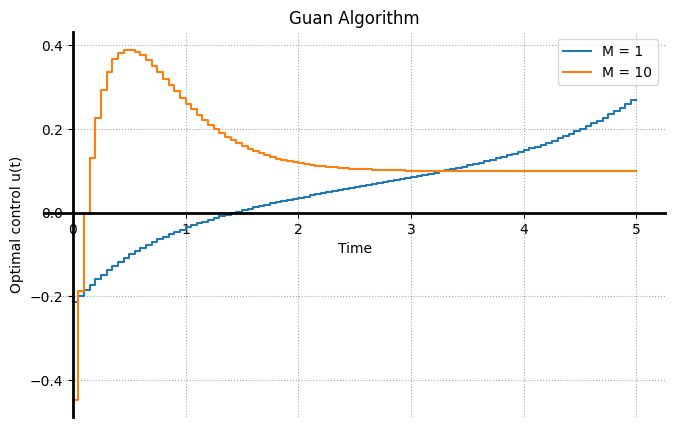

In [1]:
# guan
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

torch.set_default_dtype(torch.float64)
torch.manual_seed(42)

# Problem parameters
p1 = 2.0
p2 = 1.0
c = 1.0
K = 0.25
x0 = 0.5
T = 5.0
M_values = [1.0, 10.0]

N = 100
dt = T/N


class ControlNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 8),
            nn.Tanh(),
            nn.Linear(8, 12),
            nn.Tanh(),
            nn.Linear(12, N)
        )

    def forward(self, z):
        return self.net(z).squeeze()


def solve_for_M(M):
    model = ControlNet()
    optimizer = optim.Adam(model.parameters(), lr=0.005)
    z_input = torch.tensor([[1.0]])

    start = time.time()

    for epoch in range(500):
        optimizer.zero_grad()
        xi = model(z_input)

        x_values = [torch.tensor(x0)]

        # Euler method for the state equation
        for j in range(N):
            x = x_values[-1]
            u = xi[j]
            dx = K*x*(M-x) - u*x
            x_values.append(x + dt*dx)

        x_values = torch.stack(x_values)

        # Discretized objective
        objective = 0.0
        for j in range(N):
            x_mid = 0.5*(x_values[j] + x_values[j+1])
            u = xi[j]
            objective = objective + (
                p1*u*x_mid - p2*u**2*x_mid**2 - c*u
            )*dt

        loss = -objective
        loss.backward()
        optimizer.step()

    elapsed = time.time()-start

    with torch.no_grad():
        optimal_u = model(z_input).numpy()

    print("M =", M, "Final loss:", loss.item())
    print("M =", M, "Training time:", elapsed, "seconds")

    t_plot = []
    u_plot = []
    for j in range(N):
        t_plot.extend([j*dt, (j+1)*dt])
        u_plot.extend([optimal_u[j], optimal_u[j]])

    return t_plot, u_plot


plt.figure(figsize=(8, 5))

for M in M_values:
    t_plot, u_plot = solve_for_M(M)
    plt.plot(t_plot, u_plot, label=f"M = {M:g}")

plt.xlabel("Time")
plt.ylabel("Optimal control u(t)")
plt.title("Guan Algorithm")
plt.legend()
plt.grid(True, linestyle=':', color='gray', alpha=0.7)

ax = plt.gca()

# Hide top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Make x=0 (y-axis) and y=0 (x-axis) prominent and position them at the origin
ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_position('zero')

ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

plt.show()

## **10.2: Problem 2 (Guan)**

In [ ]:
#guan
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

torch.set_default_dtype(torch.float64)
torch.manual_seed(42)

class ControlNet(nn.Module):
    def __init__(self, num_subintervals=15):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 12), nn.Tanh(),
            nn.Linear(12, 12), nn.Tanh(),
            nn.Linear(12, num_subintervals), nn.Sigmoid())
    def forward(self, z):
        return 2.0 * self.net(z)

N = 80
t0, tf = 0.0, 2.0
dt = (tf - t0) / N
t_grid = torch.linspace(t0, tf, N + 1)
max_epochs = 250
tolerance = 1e-8        # Convergence tolerance for change in loss between consecutive epochs

model = ControlNet(num_subintervals=N)
optimizer = optim.Adam(model.parameters(), lr=0.01)
z_input = torch.tensor([[1.0]])

prev_loss = float('inf')

start = time.time()
for epoch in range(max_epochs):
    optimizer.zero_grad()
    xi = model(z_input).squeeze()
    x_states = [torch.tensor(5.0)]

    # Euler method
    for k in range(N):
        x_next = x_states[-1] + dt * (x_states[-1] + xi[k])
        x_states.append(x_next)
    x_states = torch.stack(x_states)

    objective_integral = 0.0
    for k in range(N):
        x_mid = 0.5 * (x_states[k] + x_states[k + 1])
        u_k = xi[k]
        objective_integral = objective_integral + (2 * x_mid - 3 * u_k - u_k**2) * dt

    loss = -objective_integral
    current_loss = loss.item()
    """
    # Check convergence via difference between consecutive losses
    if abs(current_loss - prev_loss) < tolerance:
        print(f"Tolerance ({tolerance}) reached at epoch {epoch + 1}. Stopping early.")
        break
    prev_loss = current_loss
    """
    loss.backward()
    optimizer.step()
end = time.time()

with torch.no_grad():
    xi = model(z_input).squeeze()
    x_states = [torch.tensor(5.0)]
    for k in range(N):
        x_states.append(x_states[-1] + dt * (x_states[-1] + xi[k]))
    x_states = torch.stack(x_states)
    x_sol = x_states.numpy()
    u_sol = xi.numpy()

t_plot = np.linspace(0, 2, 300)
t1 = 2 - np.log(9 / 2)
t2 = 2 - np.log(5 / 2)
u_exact = np.piecewise(t_plot, [t_plot < t1, (t_plot >= t1) & (t_plot <= t2), t_plot > t2],
    [2.0, lambda t: np.exp(2 - t) - 2.5, 0.0])
x_exact = np.piecewise(t_plot, [t_plot <= t1, (t_plot > t1) & (t_plot <= t2), t_plot > t2],
    [lambda t: 7 * np.exp(t) - 2,
     lambda t: (7 - (81 / 8) * np.exp(-2)) * np.exp(t) - 0.5 * np.exp(2 - t) + 2.5,
     lambda t: (7 - 7 * np.exp(-2)) * np.exp(t)])

print("Final loss:", loss.item())
print("Training time:", end - start, "seconds")

plt.figure(figsize=(7, 5))
plt.plot(t_plot, x_exact, 'r-', label='Exact solution')
plt.plot(t_grid.numpy(), x_sol, 'g--', label='NN solution')
plt.xlabel('Time'); plt.ylabel('x(t)'); plt.title('State'); plt.legend(); plt.grid(); plt.show()

t_control, u_control = [], []
for k in range(N):
    t_control.extend([k * dt, (k + 1) * dt])
    u_control.extend([u_sol[k], u_sol[k]])
plt.figure(figsize=(7, 5))
plt.plot(t_plot, u_exact, 'r-', label='Exact solution')
plt.plot(t_control, u_control, 'b--', label='NN control')
plt.xlabel('Time'); plt.ylabel('u(t)'); plt.title('Control')
plt.ylim(-0.2, 2.2); plt.legend(); plt.grid(); plt.show()

## **10.3 (a-d): Problem 2 (Sohrab and Ali)**

Final PMP loss: 2.1968352095436486e-06
Training time: 30.905458688735962 seconds


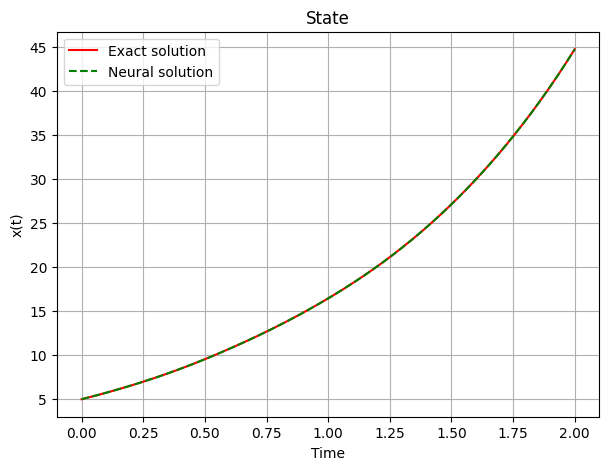

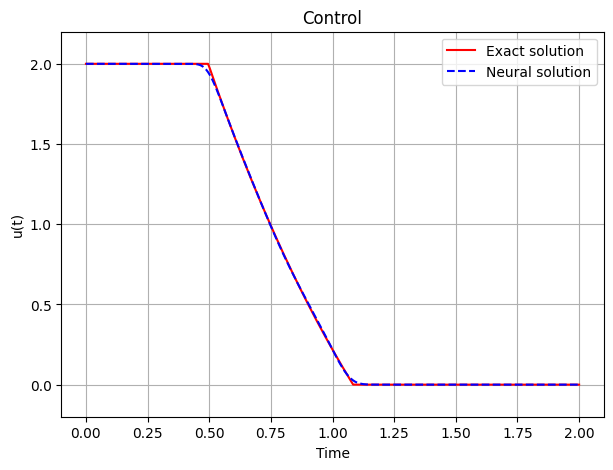

In [ ]:
#(a)-(b) sohrab algorithm
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time

torch.set_default_dtype(torch.float64)
torch.manual_seed(42)
T, M, neurons = 2.0, 15, 12
t_points = torch.linspace(0, T, M).reshape(-1, 1)

class NeuralNetwork(nn.Module):
    def __init__(self, outputs):
        super().__init__()
        self.hidden1 = nn.Linear(1, neurons)
        self.hidden2 = nn.Linear(neurons, neurons)
        self.output = nn.Linear(neurons, outputs)
    def forward(self, t):
        z = torch.tanh(self.hidden1(t))
        z = torch.tanh(self.hidden2(z))
        return self.output(z)

x_nn = NeuralNetwork(1)
p_nn = NeuralNetwork(1)
u_nn = NeuralNetwork(1)

def trial_solutions(t):
    x = 5.0 + t * x_nn(t)
    p = (t - T) * p_nn(t)
    u = 2.0 * torch.sigmoid(u_nn(t))
    return x, p, u

def time_derivative(y, t):
    return torch.autograd.grad(y.sum(), t, create_graph=True)[0]

def calculate_loss():
    t = t_points.clone().detach().requires_grad_(True)
    x, p, u = trial_solutions(t)
    dx = time_derivative(x, t)
    dp = time_derivative(p, t)
    E1 = dx - x - u
    E2 = dp + 2.0 + p
    u_opt = torch.clamp((p - 3.0) / 2.0, min=0.0, max=2.0)
    E3 = u - u_opt
    return torch.sum(E1**2) + torch.sum(E2**2) + torch.sum(E3**2)

parameters = list(x_nn.parameters()) + list(p_nn.parameters()) + list(u_nn.parameters())

start = time.time()

# 1. Warmup with Adam so p(t) rises above 3.0 and escapes the u=0 clamp zone
adam = torch.optim.Adam(parameters, lr=0.01)
for epoch in range(100):
    adam.zero_grad()
    loss = calculate_loss()
    loss.backward()
    adam.step()

# 2. Polish with LBFGS for high precision
optimizer = torch.optim.LBFGS(parameters, lr=1.0, max_iter=5000,
    tolerance_grad=1e-4, tolerance_change=1e-14, line_search_fn="strong_wolfe")

def closure():
    optimizer.zero_grad()
    loss = calculate_loss()
    loss.backward()
    return loss

for _ in range(3):
    optimizer.step(closure)

end = time.time()

print("Final PMP loss:", calculate_loss().item())
print("Training time:", end - start, "seconds")

t_plot = np.linspace(0, 2, 300)
t_tensor = torch.tensor(t_plot).reshape(-1, 1)
with torch.no_grad():
    x_sol, p_sol, u_sol = trial_solutions(t_tensor)
x_sol = x_sol.numpy().flatten()
u_sol = u_sol.numpy().flatten()

t1 = 2 - np.log(9 / 2)
t2 = 2 - np.log(5 / 2)
u_exact = np.piecewise(t_plot, [t_plot < t1, (t_plot >= t1) & (t_plot <= t2), t_plot > t2],
    [2.0, lambda t: np.exp(2 - t) - 2.5, 0.0])
x_exact = np.piecewise(t_plot, [t_plot <= t1, (t_plot > t1) & (t_plot <= t2), t_plot > t2],
    [lambda t: 7 * np.exp(t) - 2,
     lambda t: (7 - 81 / 8 * np.exp(-2)) * np.exp(t) - 0.5 * np.exp(2 - t) + 2.5,
     lambda t: (7 - 7 * np.exp(-2)) * np.exp(t)])

plt.figure(figsize=(7, 5))
plt.plot(t_plot, x_exact, 'r-', label='Exact solution')
plt.plot(t_plot, x_sol, 'g--', label='Neural solution')
plt.xlabel('Time'); plt.ylabel('x(t)'); plt.title('State'); plt.legend(); plt.grid(); plt.show()

plt.figure(figsize=(7, 5))
plt.plot(t_plot, u_exact, 'r-', label='Exact solution')
plt.plot(t_plot, u_sol, 'b--', label='Neural solution')
plt.xlabel('Time'); plt.ylabel('u(t)'); plt.title('Control')
plt.ylim(-0.2, 2.2); plt.legend(); plt.grid(); plt.show()

Iteration 1, PMP Update Loss: 23.53490291
Iteration 2, PMP Update Loss: 5.89152694
Iteration 3, PMP Update Loss: 1.81975102
Iteration 4, PMP Update Loss: 0.51820948
Iteration 5, PMP Update Loss: 0.14866998
Iteration 6, PMP Update Loss: 0.04232663
Iteration 7, PMP Update Loss: 0.01322809
Iteration 8, PMP Update Loss: 0.00392963
Iteration 9, PMP Update Loss: 0.00119067
Iteration 10, PMP Update Loss: 0.00052022
Iteration 11, PMP Update Loss: 0.00048779
Iteration 12, PMP Update Loss: 0.00040454
Iteration 13, PMP Update Loss: 0.00032484
Iteration 14, PMP Update Loss: 0.00022515
Iteration 15, PMP Update Loss: 0.00016458
Iteration 16, PMP Update Loss: 0.00014823
Iteration 17, PMP Update Loss: 0.00012324
Iteration 18, PMP Update Loss: 0.00014093
Iteration 19, PMP Update Loss: 0.00011460
Iteration 20, PMP Update Loss: 0.00009999
Tolerance (0.0001) reached at iteration 20. Stopping early.
Final Ali update loss: 9.999307896120082e-05
Training time: 79.39670467376709 seconds


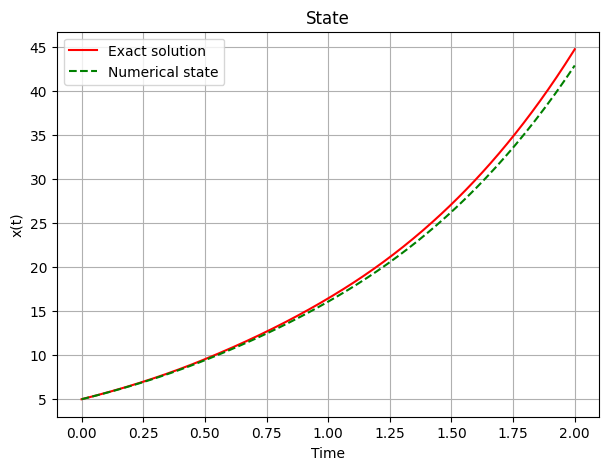

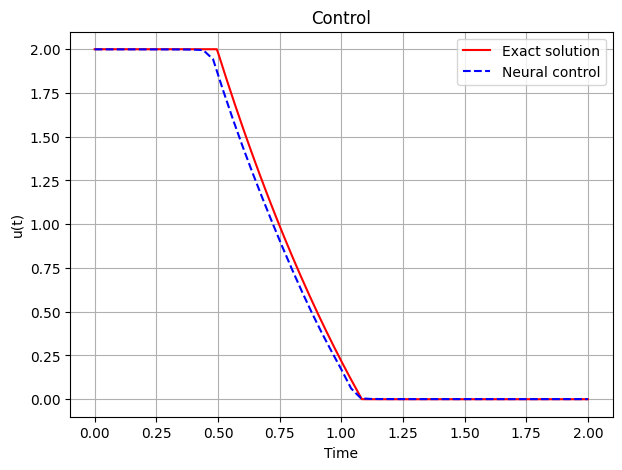

In [ ]:
# (c)-(d) ali algorithm
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time

torch.set_default_dtype(torch.float64)
torch.manual_seed(42)
np.random.seed(42)

T = 2.0
N = 50                 # Finer grid (dt = 0.02) to reduce Euler truncation error
dt = T / N
neurons = 12
iterations = 250
k1 = 1.0
k2 = 1.0
tolerance = 1e-4         # Error tolerance threshold for optimizer stopping
t_points = torch.linspace(0, T, N + 1).reshape(-1, 1)
t_numpy = t_points.numpy().flatten()
in_itr = 700

class NeuralNetwork(nn.Module):
    def __init__(self, inputs, outputs):
        super().__init__()
        self.hidden1 = nn.Linear(inputs, neurons)
        self.hidden2 = nn.Linear(neurons, neurons)
        self.output = nn.Linear(neurons, outputs)
    def forward(self, z):
        z = torch.tanh(self.hidden1(z))
        z = torch.tanh(self.hidden2(z))
        return self.output(z)

u_nn = NeuralNetwork(1, 1)
x_nn = NeuralNetwork(2, 1)
p_nn = NeuralNetwork(3, 1)

def solve_state_costate(u_values):
    x_values = np.zeros(N + 1)
    x_values[0] = 5.0
    # Forward Euler for x' = x + u
    for k in range(N):
        x_values[k + 1] = x_values[k] + dt * (x_values[k] + u_values[k])

    p_values = np.zeros(N + 1)
    p_values[N] = 0.0
    # Backward Euler stepping for p' = -(2 + p)
    for k in range(N - 1, -1, -1):
        p_values[k] = p_values[k + 1] + dt * (2.0 + p_values[k + 1])
    return x_values, p_values

u_values = np.ones(N + 1)
start = time.time()
update_loss = torch.tensor(float('inf'))

for iteration in range(iterations):
    x_values, p_values = solve_state_costate(u_values)
    u_data = torch.tensor(u_values).reshape(-1, 1)
    x_data = torch.tensor(x_values).reshape(-1, 1)
    p_data = torch.tensor(p_values).reshape(-1, 1)

    # Train control network
    optimizer_u = torch.optim.Adam(u_nn.parameters(), lr=0.01)
    for epoch in range(in_itr):
        optimizer_u.zero_grad()
        u_pred = 2.0 * torch.sigmoid(u_nn(t_points))
        loss_u = torch.sum((u_pred - u_data)**2)
        if loss_u.item() < tolerance:
            break
        loss_u.backward()
        optimizer_u.step()

    # Train state network
    optimizer_x = torch.optim.Adam(x_nn.parameters(), lr=0.01)
    for epoch in range(in_itr):
        optimizer_x.zero_grad()
        u_pred = 2.0 * torch.sigmoid(u_nn(t_points))
        x_pred = x_nn(torch.cat((t_points, u_pred), dim=1))
        loss_x = torch.sum((x_pred - x_data)**2)
        if loss_x.item() < tolerance:
            break
        loss_x.backward()
        optimizer_x.step()

    # Train costate network
    optimizer_p = torch.optim.Adam(p_nn.parameters(), lr=0.01)
    for epoch in range(in_itr):
        optimizer_p.zero_grad()
        u_pred = 2.0 * torch.sigmoid(u_nn(t_points))
        x_pred = x_nn(torch.cat((t_points, u_pred), dim=1))
        p_pred = p_nn(torch.cat((t_points, u_pred, x_pred), dim=1))
        loss_p = torch.sum((p_pred - p_data)**2)
        if loss_p.item() < tolerance:
            break
        loss_p.backward()
        optimizer_p.step()

    with torch.no_grad():
        u_previous = (2.0 * torch.sigmoid(u_nn(t_points))).detach()

    # Freeze surrogate networks during control update
    for param in x_nn.parameters():
        param.requires_grad = False
    for param in p_nn.parameters():
        param.requires_grad = False

    # Update control using projected PMP loss with inner tolerance stopping
    optimizer_u = torch.optim.Adam(u_nn.parameters(), lr=0.005)
    for epoch in range(in_itr):
        optimizer_u.zero_grad()
        u_pred = 2.0 * torch.sigmoid(u_nn(t_points))
        x_pred = x_nn(torch.cat((t_points, u_pred), dim=1))
        p_pred = p_nn(torch.cat((t_points, u_pred, x_pred), dim=1))

        # Projected Hamiltonian maximizer on [0, 2]
        u_opt = torch.clamp((p_pred - 3.0) / 2.0, min=0.0, max=2.0)

        difference_loss = torch.sum((u_pred - u_previous)**2)
        hamiltonian_loss = torch.sum((u_pred - u_opt)**2)
        update_loss = k1 * difference_loss + k2 * hamiltonian_loss
        if update_loss.item() < tolerance:
            break
        update_loss.backward()
        optimizer_u.step()

    for param in x_nn.parameters():
        param.requires_grad = True
    for param in p_nn.parameters():
        param.requires_grad = True

    print(f"Iteration {iteration + 1}, PMP Update Loss: {update_loss.item():.8f}")
    if update_loss.item() < tolerance:
        print(f"Tolerance ({tolerance}) reached at iteration {iteration + 1}. Stopping early.")
        break

    with torch.no_grad():
        u_values = (2.0 * torch.sigmoid(u_nn(t_points))).numpy().flatten()

end = time.time()
x_values, p_values = solve_state_costate(u_values)

t_plot = np.linspace(0, 2, 300)
t1 = 2 - np.log(9 / 2)
t2 = 2 - np.log(5 / 2)
u_exact = np.piecewise(t_plot, [t_plot < t1, (t_plot >= t1) & (t_plot <= t2), t_plot > t2],
    [2.0, lambda t: np.exp(2 - t) - 2.5, 0.0])
x_exact = np.piecewise(t_plot, [t_plot <= t1, (t_plot > t1) & (t_plot <= t2), t_plot > t2],
    [lambda t: 7 * np.exp(t) - 2,
     lambda t: (7 - 81 / 8 * np.exp(-2)) * np.exp(t) - 0.5 * np.exp(2 - t) + 2.5,
     lambda t: (7 - 7 * np.exp(-2)) * np.exp(t)])

print("Final Ali update loss:", update_loss.item())
print("Training time:", end - start, "seconds")

plt.figure(figsize=(7, 5))
plt.plot(t_plot, x_exact, 'r-', label='Exact solution')
plt.plot(t_numpy, x_values, 'g--', label='Numerical state')
plt.xlabel('Time'); plt.ylabel('x(t)'); plt.title('State'); plt.legend(); plt.grid(); plt.show()

plt.figure(figsize=(7, 5))
plt.plot(t_plot, u_exact, 'r-', label='Exact solution')
plt.plot(t_numpy, u_values, 'b--', label='Neural control')
plt.xlabel('Time'); plt.ylabel('u(t)'); plt.title('Control'); plt.legend(); plt.grid(); plt.show()

## **10.4 (a)(b): Reproductive Strategies in social insects**

Final objective loss (-q(T)): -166.76082299520107
Final q(T): 166.76082299520107
Training time: 3.962660312652588 seconds


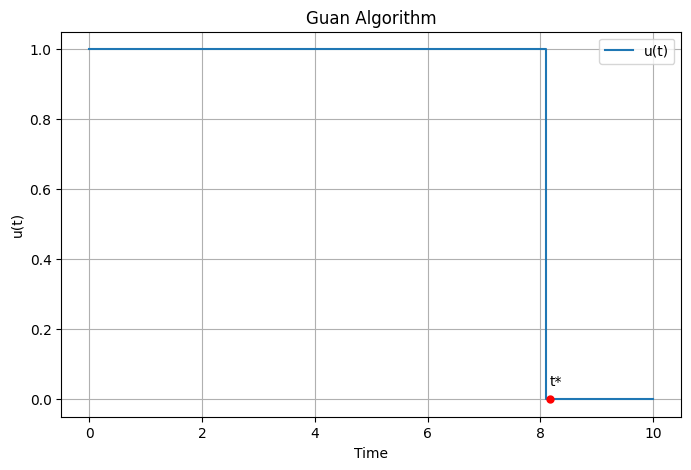

In [4]:
# (a) guan algorithm

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time

torch.set_default_dtype(torch.float64)
torch.manual_seed(42)
mu, nu, b, c, s = 0.2, 0.1, 1.0, 0.8, 0.6
w0, q0, T = 10.0, 0.0, 10.0

N=100
dt=T/N

class ControlNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(1,64),nn.Tanh(),
            nn.Linear(64,64),nn.Tanh(),nn.Linear(64,N),nn.Sigmoid())
    def forward(self,z):
        return self.net(z).squeeze()

model=ControlNet()
opt=torch.optim.Adam(model.parameters(),lr=0.01)
z=torch.tensor([[1.0]])
start=time.time()

for epoch in range(250):
    opt.zero_grad()
    xi=model(z)
    ws=[torch.tensor(w0)]
    qs=[torch.tensor(q0)]
    for j in range(N):
        w,q=ws[-1],qs[-1]
        u=xi[j]
        ws.append(w+dt*(-mu*w+b*s*u*w))
        qs.append(q+dt*(-nu*q+c*s*(1-u)*w))
    ws,qs=torch.stack(ws),torch.stack(qs)
    loss=-qs[-1]
    loss.backward()
    opt.step()

elapsed=time.time()-start
print("Final objective loss (-q(T)):",loss.item())
print("Final q(T):",qs[-1].item())
print("Training time:",elapsed,"seconds")

with torch.no_grad():
    u=model(z).numpy()
tt,uu=[],[]
for j in range(N):
    tt.extend([j*dt,(j+1)*dt])
    uu.extend([u[j],u[j]])
plt.figure(figsize=(8,5))
plt.plot(tt,uu,label="u(t)")
t_star = 8.1768
plt.plot(t_star, 0.0, 'ro', markersize=5)
plt.annotate("t*", xy=(t_star, 0.0), xytext=(t_star+0.1, 0.04), ha="center")
plt.xlabel("Time"); plt.ylabel("u(t)"); plt.title("Guan Algorithm")
plt.ylim(-0.05,1.05); plt.grid(); plt.legend(); plt.show()

Final Ali update loss: 0.17413964651811278
Final q(T): 166.52148791590992
Training time: 22.23672366142273 seconds


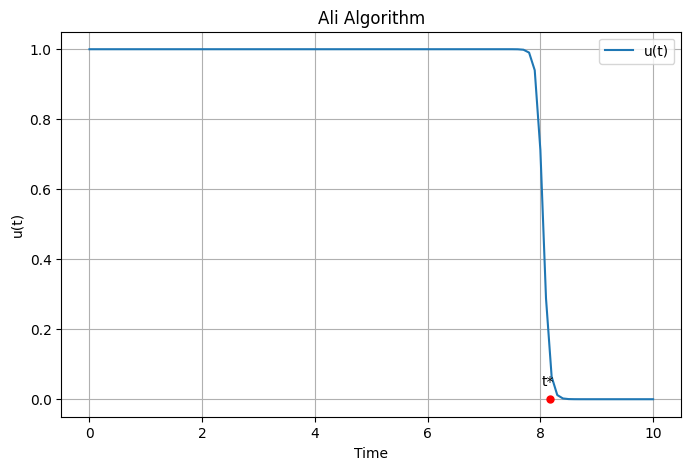

In [5]:
# (b) ali algorithm

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time

torch.set_default_dtype(torch.float64)
torch.manual_seed(42)
mu, nu, b, c, s = 0.2, 0.1, 1.0, 0.8, 0.6
w0, q0, T = 10.0, 0.0, 10.0

N,neurons,iterations=100,64,20
dt=T/N
k1=k2=1.0
t_points=torch.linspace(0,T,N+1).reshape(-1,1)
t_numpy=t_points.numpy().flatten()

class Net(nn.Module):
    def __init__(self,nout):
        super().__init__()
        self.hidden=nn.Linear(1,neurons)
        self.output=nn.Linear(neurons,nout)
    def forward(self,t):
        return self.output(torch.sigmoid(self.hidden(t)))

u_nn,x_nn,p_nn=Net(1),Net(2),Net(2)
def get_u():
    return torch.sigmoid(u_nn(t_points))

def solve_x(u):
    x=np.zeros((N+1,2)); x[0]=[w0,q0]
    for j in range(N):
        w,q=x[j]
        x[j+1]=x[j]+dt*np.array([-mu*w+b*s*u[j]*w,
                                  -nu*q+c*s*(1-u[j])*w])
    return x

def solve_p(x,u):
    p=np.zeros((N+1,2)); p[N]=[0.0,1.0]
    for j in range(N-1,-1,-1):
        w,q=x[j+1]; pw,pq=p[j+1]
        Hw=pw*(-mu+b*s*u[j])+pq*c*s*(1-u[j])
        Hq=-nu*pq
        p[j]=p[j+1]+dt*np.array([Hw,Hq])
    return p

u_values=np.full(N+1,0.5)
start=time.time()
for iteration in range(iterations):
    states=solve_x(u_values)
    costates=solve_p(states,u_values)
    ud=torch.tensor(u_values).reshape(-1,1)
    xd=torch.tensor(states)
    pd=torch.tensor(costates)

    opt=torch.optim.Adam(u_nn.parameters(),lr=0.01)
    for epoch in range(500):
        opt.zero_grad()
        L=torch.sum((get_u()-ud)**2); L.backward(); opt.step()

    opt=torch.optim.Adam(x_nn.parameters(),lr=0.01)
    for epoch in range(500):
        opt.zero_grad()
        L=torch.sum((x_nn(t_points)-xd)**2); L.backward(); opt.step()

    opt=torch.optim.Adam(p_nn.parameters(),lr=0.01)
    for epoch in range(500):
        opt.zero_grad()
        L=torch.sum((p_nn(t_points)-pd)**2); L.backward(); opt.step()

    with torch.no_grad():
        uold=get_u().detach()

    for par in x_nn.parameters(): par.requires_grad=False
    for par in p_nn.parameters(): par.requires_grad=False
    opt=torch.optim.Adam(u_nn.parameters(),lr=0.001)
    for epoch in range(500):
        opt.zero_grad()
        u=get_u(); x=x_nn(t_points); p=p_nn(t_points)
        w=x[:,0:1]; pw=p[:,0:1]; pq=p[:,1:2]
        Hu=s*w*(b*pw-c*pq)
        uopt=torch.where(Hu>=0,torch.ones_like(Hu),torch.zeros_like(Hu))
        difference=torch.sum((u-uold)**2)
        pmp=torch.sum((u-uopt)**2)
        update_loss=k1*difference+k2*pmp
        update_loss.backward(); opt.step()
    for par in x_nn.parameters(): par.requires_grad=True
    for par in p_nn.parameters(): par.requires_grad=True
    with torch.no_grad():
        u_values=get_u().numpy().flatten()

elapsed=time.time()-start
print("Final Ali update loss:",update_loss.item())
print("Final q(T):",solve_x(u_values)[-1,1])
print("Training time:",elapsed,"seconds")
with torch.no_grad():
    u=get_u().numpy().flatten()
plt.figure(figsize=(8,5))
plt.plot(t_numpy,u,label="u(t)")
t_star = 8.1768
plt.plot(t_star, 0.0, 'ro', markersize=5)
plt.annotate("t*", xy=(t_star, 0.0), xytext=(t_star-0.05, 0.04), ha="center")
plt.xlabel("Time"); plt.ylabel("u(t)"); plt.title("Ali Algorithm")
plt.ylim(-0.05,1.05); plt.grid(); plt.legend(); plt.show()


## **10.6 (a)(b): Two Compartment Model in Cancer Chemotherapy**

Final objective loss: 10.739977885501162
Training time: 3.750131130218506 seconds


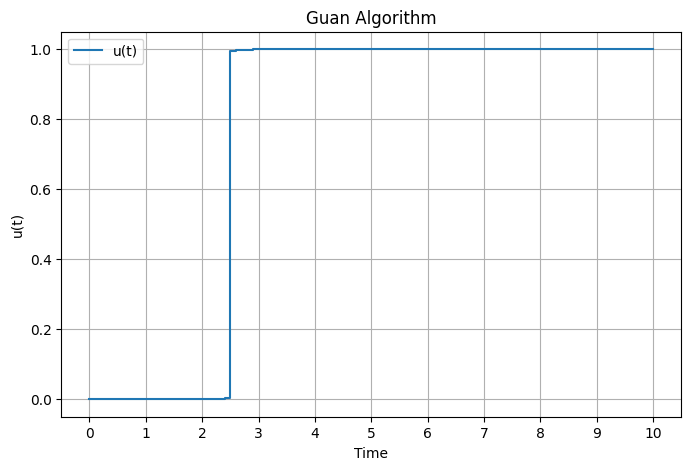

In [3]:
#(a) guan algorithm
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

torch.set_default_dtype(torch.float64)
torch.manual_seed(42)

a1, a2 = 0.197, 0.356
r1, r2 = 6.94, 3.94
N10, N20 = 0.87, 0.55
T = 10.0
N = 100
dt = T/N

class ControlNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1,64),nn.Tanh(),
            nn.Linear(64,64),nn.Tanh(),nn.Linear(64,N),nn.Sigmoid())
    def forward(self,z):
        return self.net(z).squeeze()

model = ControlNet()
optimizer = optim.Adam(model.parameters(),lr=0.01)
z = torch.tensor([[1.0]])
start = time.time()

for epoch in range(250):
    optimizer.zero_grad()
    xi = model(z)
    N1s = [torch.tensor(N10)]
    N2s = [torch.tensor(N20)]

    # Euler method
    for j in range(N):
        N1,N2 = N1s[-1],N2s[-1]
        u = xi[j]
        N1s.append(N1+dt*(-a1*N1+2*(1-u)*a2*N2))
        N2s.append(N2+dt*(a1*N1-a2*N2))

    N1s,N2s = torch.stack(N1s),torch.stack(N2s)
    objective = r1*N1s[-1]+r2*N2s[-1]
    for j in range(N):
        objective = objective+xi[j]*dt
    loss = objective
    loss.backward()
    optimizer.step()

end = time.time()
print("Final objective loss:",loss.item())
print("Training time:",end-start,"seconds")
with torch.no_grad():
    u = model(z).numpy()
tplot, uplot = [], []
for j in range(N):
    tplot.extend([j*dt,(j+1)*dt])
    uplot.extend([u[j],u[j]])
plt.figure(figsize=(8,5))
plt.plot(tplot,uplot,label="u(t)")
plt.xticks(np.arange(0, 11, 1))
plt.xlabel("Time"); plt.ylabel("u(t)")
plt.title("Guan Algorithm"); plt.ylim(-0.05,1.05)
plt.legend(); plt.grid(); plt.show()

Final Ali update loss: 0.15823175066037046
Training time: 13.063886880874634 seconds


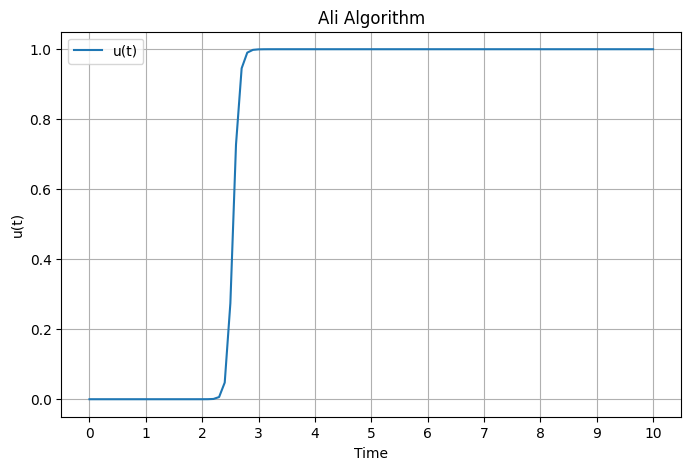

In [2]:
# (b) ali algorithm
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time

torch.set_default_dtype(torch.float64)
torch.manual_seed(42)
np.random.seed(42)

a1, a2 = 0.197, 0.356
r1, r2 = 6.94, 3.94
N10, N20 = 0.87, 0.55
T = 10.0
N, neurons, iterations = 100, 24, 20
dt = T/N
k1 = k2 = 1.0
t_points = torch.linspace(0,T,N+1).reshape(-1,1)
t_numpy = t_points.numpy().flatten()

class Net(nn.Module):
    def __init__(self, outputs):
        super().__init__()
        self.hidden = nn.Linear(1,neurons)
        self.output = nn.Linear(neurons,outputs)
    def forward(self,t):
        return self.output(torch.sigmoid(self.hidden(t)))

u_nn, x_nn, p_nn = Net(1), Net(2), Net(2)

def get_u():
    return torch.sigmoid(u_nn(t_points))

def solve_states(u):
    x = np.zeros((N+1,2))
    x[0] = [N10,N20]
    for j in range(N):
        N1,N2 = x[j]
        x[j+1,0] = N1+dt*(-a1*N1+2*(1-u[j])*a2*N2)
        x[j+1,1] = N2+dt*(a1*N1-a2*N2)
    return x

def solve_costates(x,u):
    p = np.zeros((N+1,2))
    p[N] = [r1,r2]
    for j in range(N-1,-1,-1):
        N1,N2 = x[j+1]
        p1,p2 = p[j+1]
        HN1 = -a1*p1+a1*p2
        HN2 = 2*(1-u[j])*a2*p1-a2*p2
        p[j] = p[j+1]+dt*np.array([HN1,HN2])
    return p

u_values = np.full(N+1,0.5)
start = time.time()

for iteration in range(iterations):
    states = solve_states(u_values)
    costates = solve_costates(states,u_values)
    u_data = torch.tensor(u_values).reshape(-1,1)
    x_data = torch.tensor(states)
    p_data = torch.tensor(costates)

    opt = torch.optim.Adam(u_nn.parameters(),lr=0.01)
    for epoch in range(300):
        opt.zero_grad()
        err = torch.sum((get_u()-u_data)**2)
        err.backward()
        opt.step()

    opt = torch.optim.Adam(x_nn.parameters(),lr=0.01)
    for epoch in range(300):
        opt.zero_grad()
        err = torch.sum((x_nn(t_points)-x_data)**2)
        err.backward()
        opt.step()

    opt = torch.optim.Adam(p_nn.parameters(),lr=0.01)
    for epoch in range(300):
        opt.zero_grad()
        err = torch.sum((p_nn(t_points)-p_data)**2)
        err.backward()
        opt.step()

    with torch.no_grad():
        u_previous = get_u().detach()

    for par in x_nn.parameters(): par.requires_grad = False
    for par in p_nn.parameters(): par.requires_grad = False

    opt = torch.optim.Adam(u_nn.parameters(),lr=0.001)
    for epoch in range(300):
        opt.zero_grad()
        u = get_u()
        x = x_nn(t_points)
        p = p_nn(t_points)
        N2 = x[:,1:2]
        p1 = p[:,0:1]
        Hu = 1-2*a2*p1*N2
        u_opt = torch.where(Hu >= 0,torch.zeros_like(Hu),torch.ones_like(Hu))
        difference = torch.sum((u-u_previous)**2)
        hamiltonian = torch.sum((u-u_opt)**2)
        update_loss = k1*difference+k2*hamiltonian
        update_loss.backward()
        opt.step()

    for par in x_nn.parameters(): par.requires_grad = True
    for par in p_nn.parameters(): par.requires_grad = True
    with torch.no_grad():
        u_values = get_u().numpy().flatten()

end = time.time()
print("Final Ali update loss:",update_loss.item())
print("Training time:",end-start,"seconds")
with torch.no_grad():
    u = get_u().numpy().flatten()
plt.figure(figsize=(8,5))
plt.plot(t_numpy,u,label="u(t)")
plt.xlabel("Time"); plt.ylabel("u(t)")
plt.xticks(np.arange(0, 11, 1))
plt.title("Ali Algorithm"); plt.ylim(-0.05,1.05)
plt.legend(); plt.grid(); plt.show()
